# WY2021 seasonal-site forcing preparation

PPSA, TRAM, and HEEN use their established HRRR-AK-only soil configurations and 1.2 °C rain–snow threshold. Each new run replays the original HRRR-AK lapse-rate forcing through WY2020 and switches on October 1, 2020 UTC. The containing 1,000 m or 500 m cell provides all WY2021 fields. No additional temperature lapse rate is applied.

The [preparation and run script](run_seasonal_topopyscale.py) writes the new SMET, soil profile, INI, and run outputs to each site's existing directory in run_snowpack. This notebook reads those files and audits the chosen cells and forcing.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
candidates = [cwd]
for parent in (cwd, *cwd.parents):
    candidates.extend((parent / "modeling/downscaling",
                       parent / "juneau_snow_modeling_manuscript/modeling/downscaling"))
folder = next((p for p in candidates if (p / "run_seasonal_topopyscale.py").is_file()), None)
if folder is None:
    raise FileNotFoundError("Open from the manuscript repository or the repos workspace.")
sys.path.insert(0, str(folder))
from run_seasonal_topopyscale import RESOLUTIONS, SITES, YEAR, locations, model_output, read_smet

labels = {None:"HRRR-AK lapse-rate", 1000:"TopoPyScale 1,000 m", 500:"TopoPyScale 500 m"}
colors = {None:"#525252",1000:"#bc551d",500:"#006f79"}
rows = []
forcing = {}
for site in SITES:
    for m in (None, *RESOLUTIONS):
        _, base, test = locations(site, m)
        path = base if m is None else test
        header, frame = read_smet(path.with_suffix(".smet"))
        frame = frame.reindex(YEAR)
        if not np.isfinite(frame.to_numpy()).all():
            raise ValueError(f"Incomplete WY2021 forcing: {path}")
        forcing[site,m] = frame
        if m is None:
            elevation = float(header["hrrr_elevation"].split()[0])
            site_z = float(header["altitude"])
            fallback = np.nan
        else:
            meta = json.loads(path.with_suffix(".json").read_text())
            elevation = meta["grid_elevation_m"]
            site_z = meta["site_elevation_m"]
            fallback = meta["profile_fallback_hours"]
        rows.append({"Site":site.upper(),"Forcing":labels[m],"Site elevation (m)":site_z,
                     "Source cell elevation (m)":elevation,"Cell minus site (m)":elevation-site_z,
                     "Mean air temperature (°C)":frame.TA.mean()-273.15,
                     "Precipitation (mm)":frame.PSUM.sum(),"Profile fallback hours":fallback})
display(pd.DataFrame(rows).set_index(["Site","Forcing"]).round(2))


Site elevation (m)  Source cell elevation (m)  \
Site Forcing                                                              
PPSA HRRR-AK lapse-rate               670.00                     572.00   
     TopoPyScale 1,000 m              670.00                     766.55   
     TopoPyScale 500 m                670.00                     717.02   
TRAM HRRR-AK lapse-rate               529.00                     637.39   
     TopoPyScale 1,000 m              529.00                      97.42   
     TopoPyScale 500 m                529.00                     289.30   
HEEN HRRR-AK lapse-rate               640.08                     744.00   
     TopoPyScale 1,000 m              640.08                     812.83   
     TopoPyScale 500 m                640.08                     689.54   

                          Cell minus site (m)  Mean air temperature (°C)  \
Site Forcing                                                               
PPSA HRRR-AK lapse-rate                -98.00                       1.72   
     TopoPyScale 1,000 m                96.55                       2.24   
     TopoPyScale 500 m                  47.02                       2.52   
TRAM HRRR-AK lapse-rate                108.39                       2.49   
     TopoPyScale 1,000 m              -431.58                       5.90   
     TopoPyScale 500 m                -239.70                       5.10   
HEEN HRRR-AK lapse-rate                103.92                       2.14   
     TopoPyScale 1,000 m               172.75                       1.84   
     TopoPyScale 500 m                  49.46                       2.74   

                          Precipitation (mm)  Profile fallback hours  
Site Forcing                                                          
PPSA HRRR-AK lapse-rate              3464.53                     NaN  
     TopoPyScale 1,000 m             3520.80                     0.0  
     TopoPyScale 500 m               3520.80                     0.0  
TRAM HRRR-AK lapse-rate              4910.47                     NaN  
     TopoPyScale 1,000 m             4943.44                     0.0  
     TopoPyScale 500 m               4943.44                     0.0  
HEEN HRRR-AK lapse-rate              2911.00                     NaN  
     TopoPyScale 1,000 m             2916.57                     0.0  
     TopoPyScale 500 m               2916.57                     0.0

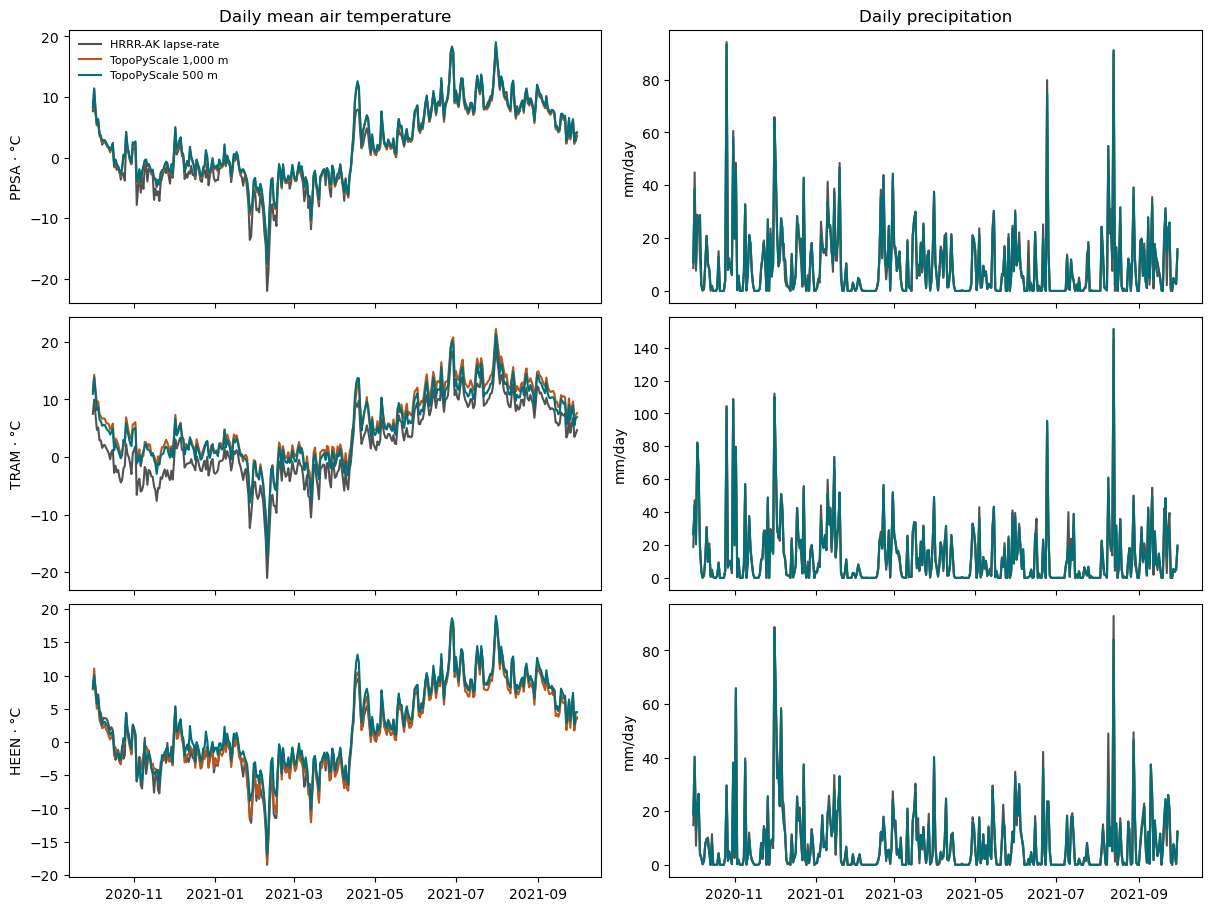

In [2]:
fig, axes = plt.subplots(3,2,figsize=(12,9),sharex=True,layout="constrained")
for i,site in enumerate(SITES):
    for m in (None,*RESOLUTIONS):
        frame = forcing[site,m]
        axes[i,0].plot(frame.TA.resample("D").mean()-273.15,color=colors[m],label=labels[m])
        axes[i,1].plot(frame.PSUM.resample("D").sum(),color=colors[m])
    axes[i,0].set_ylabel(f"{site.upper()} · °C")
    axes[i,1].set_ylabel("mm/day")
axes[0,0].set_title("Daily mean air temperature")
axes[0,1].set_title("Daily precipitation")
axes[0,0].legend(frameon=False,fontsize=8)
plt.show()
